# **4. Pemodelan Klasifikasi Sentimen (Machine Learning)**

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Load dataset hasil pelabelan (menggunakan utf-8-sig untuk Excel)
df = pd.read_csv('hasil_anotasi_badak_jawa.csv', encoding='utf-8-sig')

print("Jumlah data per sentimen:")
print(df['sentimen'].value_counts())
print("-" * 30)

Jumlah data per sentimen:
sentimen
Negatif    83
Netral     12
Positif     3
Name: count, dtype: int64
------------------------------


In [2]:
# Memisahkan fitur (teks) dan target (label)
X = df['teks_komentar']
y = df['sentimen']

# Membagi data latih dan data uji (80:20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Jumlah Data Latih: {len(X_train)} komentar")
print(f"Jumlah Data Uji  : {len(X_test)} komentar")

Jumlah Data Latih: 78 komentar
Jumlah Data Uji  : 20 komentar


In [3]:
# Inisialisasi TF-IDF
tfidf = TfidfVectorizer(max_features=1000)

# Proses TF-IDF (Fit pada data latih, transform pada data uji)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print(f"Bentuk matriks data latih: {X_train_tfidf.shape}")
print(f"Bentuk matriks data uji  : {X_test_tfidf.shape}")

Bentuk matriks data latih: (78, 547)
Bentuk matriks data uji  : (20, 547)


In [4]:
# --- 1. Model Naive Bayes ---
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)
y_pred_nb = nb_model.predict(X_test_tfidf)
acc_nb = accuracy_score(y_test, y_pred_nb)

# --- 2. Model SVM ---
svm_model = SVC(kernel='linear', random_state=42, class_weight='balanced')
svm_model.fit(X_train_tfidf, y_train)
y_pred_svm = svm_model.predict(X_test_tfidf)
acc_svm = accuracy_score(y_test, y_pred_svm)

print("=== HASIL SVM (CLASS WEIGHT) ===")
print(f"Akurasi : {acc_svm*100:.2f}%")
print(classification_report(y_test, y_pred_svm, zero_division=0))

=== HASIL SVM (CLASS WEIGHT) ===
Akurasi : 85.00%
              precision    recall  f1-score   support

     Negatif       0.85      1.00      0.92        17
      Netral       0.00      0.00      0.00         2
     Positif       0.00      0.00      0.00         1

    accuracy                           0.85        20
   macro avg       0.28      0.33      0.31        20
weighted avg       0.72      0.85      0.78        20



In [5]:
print("=== CLASSIFICATION REPORT: NAIVE BAYES ===")
print(classification_report(y_test, y_pred_nb, zero_division=0))

print("\n=== CLASSIFICATION REPORT: SVM ===")
print(classification_report(y_test, y_pred_svm, zero_division=0))

=== CLASSIFICATION REPORT: NAIVE BAYES ===
              precision    recall  f1-score   support

     Negatif       0.85      1.00      0.92        17
      Netral       0.00      0.00      0.00         2
     Positif       0.00      0.00      0.00         1

    accuracy                           0.85        20
   macro avg       0.28      0.33      0.31        20
weighted avg       0.72      0.85      0.78        20


=== CLASSIFICATION REPORT: SVM ===
              precision    recall  f1-score   support

     Negatif       0.85      1.00      0.92        17
      Netral       0.00      0.00      0.00         2
     Positif       0.00      0.00      0.00         1

    accuracy                           0.85        20
   macro avg       0.28      0.33      0.31        20
weighted avg       0.72      0.85      0.78        20



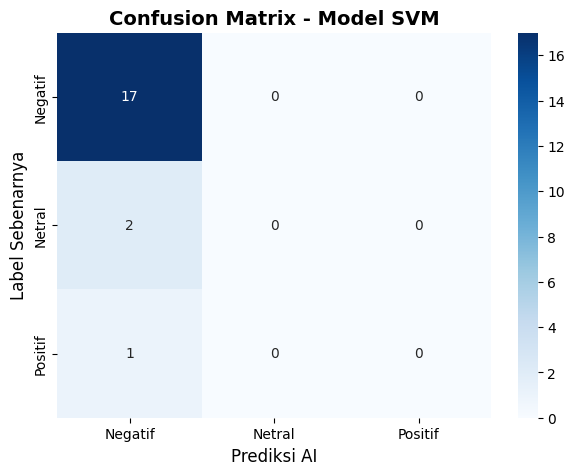

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_svm, labels=svm_model.classes_)

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=svm_model.classes_, 
            yticklabels=svm_model.classes_)
plt.title('Confusion Matrix - Model SVM', fontsize=14, fontweight='bold')
plt.xlabel('Prediksi AI', fontsize=12)
plt.ylabel('Label Sebenarnya', fontsize=12)
plt.show()